In [ ]:
# 07_ablation_study.ipynb


#  CELL 1: Setup  
from __future__ import annotations

import copy
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from PIL import Image
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
)
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

OUTPUT_DIR = Path("./data/processed")
MODEL_DIR = Path("./models")
RESULT_DIR = Path("./results")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")

torch.manual_seed(42)
np.random.seed(42)
IMG_SIZE = 224

Device: cuda


In [ ]:
#  CELL 2: Transforms  
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

In [22]:
# ==================== CELL 3: Inlined Dataset Classes ====================
EXCLUDE_COLS = {"ID", "has_cad", "max_stenosis", "num_diseased_vessels"}

def feature_columns(clinical_df):
    return [c for c in clinical_df.columns if c not in EXCLUDE_COLS]


class BaseAngioDataset(Dataset):
    def __init__(self, patient_df, frames_df=None, clinical_df=None,
                 transform=None, aggregate="mean"):
        self.patients = patient_df.reset_index(drop=True)
        self.frames = frames_df
        self.clinical = clinical_df.set_index("ID") if clinical_df is not None else None
        self.transform = transform
        self.aggregate = aggregate
        if self.clinical is not None:
            self.feature_cols = feature_columns(clinical_df)

    def __len__(self):
        return len(self.patients)

    def _load_frames(self, pid):
        subset = self.frames[self.frames["ID"] == str(int(pid))]
        tensors = []
        for path in subset["path"].tolist():
            try:
                img = Image.open(path).convert("RGB")
                tensors.append(self.transform(img) if self.transform
                               else transforms.ToTensor()(img))
            except Exception:
                continue
        return tensors

    def _aggregate(self, tensors):
        if not tensors:
            return torch.zeros(3, IMG_SIZE, IMG_SIZE)
        stack = torch.stack(tensors)
        if self.aggregate == "max":
            return stack.max(dim=0).values
        return stack.mean(dim=0)


class ImageOnlyDataset(BaseAngioDataset):
    def __getitem__(self, idx):
        row = self.patients.iloc[idx]
        img = self._aggregate(self._load_frames(int(row["ID"])))
        label = torch.tensor(int(row["has_cad"]), dtype=torch.long)
        return img, label


class ClinicalOnlyDataset(BaseAngioDataset):
    def __init__(self, patient_df, clinical_df):
        super().__init__(patient_df, frames_df=None, clinical_df=clinical_df)

    def __getitem__(self, idx):
        row = self.patients.iloc[idx]
        pid = int(row["ID"])
        clinical = self.clinical.loc[pid, self.feature_cols].values.astype(np.float32)
        label = torch.tensor(int(row["has_cad"]), dtype=torch.long)
        return torch.from_numpy(clinical), label


class FusionDataset(BaseAngioDataset):
    def __getitem__(self, idx):
        row = self.patients.iloc[idx]
        pid = int(row["ID"])
        img = self._aggregate(self._load_frames(pid))
        clinical = self.clinical.loc[pid, self.feature_cols].values.astype(np.float32)
        label = torch.tensor(int(row["has_cad"]), dtype=torch.long)
        return img, torch.from_numpy(clinical), label


# ==================== CELL 4: Inlined Model Classes ====================
class ImageOnlyModel(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.backbone = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
        feat_dim = self.backbone.fc.in_features
        self.backbone.fc = nn.Identity()
        self.classifier = nn.Sequential(
            nn.Linear(feat_dim, 128), nn.ReLU(inplace=True), nn.Dropout(0.3),
            nn.Linear(128, num_classes),
        )
    def forward(self, x):
        return self.classifier(self.backbone(x))


class ClinicalOnlyModel(nn.Module):
    def __init__(self, clinical_dim, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(clinical_dim, 128), nn.BatchNorm1d(128),
            nn.ReLU(inplace=True), nn.Dropout(0.3),
            nn.Linear(128, 64), nn.ReLU(inplace=True), nn.Dropout(0.3),
            nn.Linear(64, num_classes),
        )
    def forward(self, x):
        return self.net(x)


class ImageEncoder(nn.Module):
    def __init__(self, out_dim=256, pretrained=True):
        super().__init__()
        weights = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = models.resnet18(weights=weights)
        feat_dim = backbone.fc.in_features
        backbone.fc = nn.Identity()
        self.backbone = backbone
        self.proj = nn.Sequential(
            nn.Linear(feat_dim, out_dim), nn.ReLU(inplace=True), nn.Dropout(0.3),
        )
    def forward(self, x):
        return self.proj(self.backbone(x))


class ClinicalEncoder(nn.Module):
    def __init__(self, in_dim, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 128), nn.BatchNorm1d(128),
            nn.ReLU(inplace=True), nn.Dropout(0.3),
            nn.Linear(128, out_dim), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)


class FusionModel(nn.Module):
    def __init__(self, clinical_dim, num_classes=2):
        super().__init__()
        self.img_enc = ImageEncoder(out_dim=256)
        self.clin_enc = ClinicalEncoder(clinical_dim, out_dim=128)
        self.classifier = nn.Sequential(
            nn.Linear(256 + 128, 128), nn.ReLU(inplace=True), nn.Dropout(0.4),
            nn.Linear(128, num_classes),
        )
    def forward(self, image, clinical):
        return self.classifier(torch.cat([self.img_enc(image), self.clin_enc(clinical)], dim=1))

In [23]:
# ==================== CELL 5: Focal Loss ====================
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.25, gamma=2.0, weight=None):
        super().__init__()
        self.alpha, self.gamma = alpha, gamma
        if weight is not None:
            self.register_buffer("weight", weight)
        else:
            self.weight = None
    def forward(self, logits, targets):
        ce = nn.functional.cross_entropy(logits, targets,
                                         weight=self.weight, reduction="none")
        pt = torch.exp(-ce)
        return (self.alpha * (1.0 - pt) ** self.gamma * ce).mean()

In [24]:
# ==================== CELL 6: Training/Evaluation Helpers ====================
def train_one_epoch(model, loader, criterion, optimizer, device, model_type):
    model.train()
    running_loss = 0.0
    for batch in loader:
        optimizer.zero_grad(set_to_none=True)
        if model_type == "fusion":
            image, clinical, y = batch
            logits = model(image.to(device), clinical.to(device))
        elif model_type == "image_only":
            image, y = batch
            logits = model(image.to(device))
        else:
            clinical, y = batch
            logits = model(clinical.to(device))
        y = y.to(device)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * y.size(0)
    return running_loss / len(loader.dataset)


def evaluate(model, loader, device, model_type):
    model.eval()
    preds, probs, labels = [], [], []
    with torch.no_grad():
        for batch in loader:
            if model_type == "fusion":
                image, clinical, y = batch
                logits = model(image.to(device), clinical.to(device))
            elif model_type == "image_only":
                image, y = batch
                logits = model(image.to(device))
            else:
                clinical, y = batch
                logits = model(clinical.to(device))
            probs.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
            preds.append(logits.argmax(dim=1).cpu().numpy())
            labels.append(y.numpy())

    y_true = np.concatenate(labels)
    y_pred = np.concatenate(preds)
    y_prob = np.concatenate(probs)

    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "auc": float(roc_auc_score(y_true, y_prob)) if len(np.unique(y_true)) > 1 else 0.5,
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
    }


In [25]:
# ==================== CELL 7: Load Data ====================
clinical_df = pd.read_csv(OUTPUT_DIR / "clinical_features_merged.csv")
frames_df = pd.read_csv(OUTPUT_DIR / "frames_index.csv")
frames_df["ID"] = frames_df["ID"].astype(str)

with open(OUTPUT_DIR / "splits.json") as f:
    splits = json.load(f)

train_df = clinical_df[clinical_df["ID"].isin(splits["train"])]
val_df = clinical_df[clinical_df["ID"].isin(splits["val"])]
test_df = clinical_df[clinical_df["ID"].isin(splits["test"])]

print(f"Train {len(train_df)} | Val {len(val_df)} | Test {len(test_df)}")

Train 255 | Val 46 | Test 76


In [26]:
# ==================== CELL 8: Train Image-Only + Clinical-Only ====================
ablation_results = []
EPOCHS = 20
PATIENCE = 5

# Model 1: Image-Only
torch.manual_seed(42)
np.random.seed(42)

print("RUNNING ABLATION: Image-Only")

train_ds = ImageOnlyDataset(train_df, frames_df, clinical_df, transform=train_tfms)
val_ds = ImageOnlyDataset(val_df, frames_df, clinical_df, transform=eval_tfms)
test_ds = ImageOnlyDataset(test_df, frames_df, clinical_df, transform=eval_tfms)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True,
                          num_workers=0, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=0)

model = ImageOnlyModel().to(DEVICE)
weight_tensor = torch.tensor([2.406, 0.631], dtype=torch.float32).to(DEVICE)
criterion = FocalLoss(alpha=0.25, gamma=2.0, weight=weight_tensor)
optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

ckpt_path = MODEL_DIR / "ablation_image_only.pt"
best_auc, no_improve = -1.0, 0

for epoch in range(EPOCHS):
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer,
                                 DEVICE, "image_only")
    val_metrics = evaluate(model, val_loader, DEVICE, "image_only")

    if val_metrics["auc"] > best_auc:
        best_auc, no_improve = val_metrics["auc"], 0
        torch.save(model.state_dict(), ckpt_path)
    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break
    print(f"Epoch {epoch+1:02d} | Loss: {train_loss:.4f} | "
          f"Val AUC: {val_metrics['auc']:.4f}")

model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
test_metrics = evaluate(model, test_loader, DEVICE, "image_only")
ablation_results.append({"Model": "Image-Only", **test_metrics})

print(f"\n--- FINAL TEST: Image-Only ---")
for k, v in test_metrics.items():
    print(f"  {k:10s}: {v:.4f}")


# ---------------------------------------------------------------------------
# Model 2: Clinical-Only
# ---------------------------------------------------------------------------
torch.manual_seed(142)
np.random.seed(142)

print("RUNNING ABLATION: Clinical-Only")

train_ds = ClinicalOnlyDataset(train_df, clinical_df)
val_ds = ClinicalOnlyDataset(val_df, clinical_df)
test_ds = ClinicalOnlyDataset(test_df, clinical_df)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True,
                          num_workers=0, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=0)

clinical_dim = len(train_ds.feature_cols)
model = ClinicalOnlyModel(clinical_dim=clinical_dim).to(DEVICE)

criterion = FocalLoss(alpha=0.25, gamma=2.0, weight=weight_tensor)
optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)

ckpt_path = MODEL_DIR / "ablation_clinical_only.pt"
best_auc, no_improve = -1.0, 0

for epoch in range(EPOCHS):
    train_loss = train_one_epoch(model, train_loader, criterion, optimizer,
                                 DEVICE, "clinical_only")
    val_metrics = evaluate(model, val_loader, DEVICE, "clinical_only")

    if val_metrics["auc"] > best_auc:
        best_auc, no_improve = val_metrics["auc"], 0
        torch.save(model.state_dict(), ckpt_path)
    else:
        no_improve += 1
        if no_improve >= PATIENCE:
            print(f"Early stopping at epoch {epoch+1}")
            break
    print(f"Epoch {epoch+1:02d} | Loss: {train_loss:.4f} | "
          f"Val AUC: {val_metrics['auc']:.4f}")

model.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
test_metrics = evaluate(model, test_loader, DEVICE, "clinical_only")
ablation_results.append({"Model": "Clinical-Only", **test_metrics})

print(f"\n--- FINAL TEST: Clinical-Only ---")
for k, v in test_metrics.items():
    print(f"  {k:10s}: {v:.4f}")


RUNNING ABLATION: Image-Only
Epoch 01 | Loss: 0.0510 | Val AUC: 0.7778
Epoch 02 | Loss: 0.0466 | Val AUC: 0.5139
Epoch 03 | Loss: 0.0360 | Val AUC: 0.7333
Epoch 04 | Loss: 0.0367 | Val AUC: 0.6167
Epoch 05 | Loss: 0.0395 | Val AUC: 0.7583
Early stopping at epoch 6

--- FINAL TEST: Image-Only ---
  accuracy  : 0.6842
  auc       : 0.6969
  f1        : 0.7931
  precision : 0.8214
  recall    : 0.7667
RUNNING ABLATION: Clinical-Only
Epoch 01 | Loss: 0.0633 | Val AUC: 0.7167
Epoch 02 | Loss: 0.0493 | Val AUC: 0.7583
Epoch 03 | Loss: 0.0469 | Val AUC: 0.7861
Epoch 04 | Loss: 0.0385 | Val AUC: 0.7889
Epoch 05 | Loss: 0.0363 | Val AUC: 0.8056
Epoch 06 | Loss: 0.0356 | Val AUC: 0.8083
Epoch 07 | Loss: 0.0339 | Val AUC: 0.8056
Epoch 08 | Loss: 0.0360 | Val AUC: 0.8139
Epoch 09 | Loss: 0.0324 | Val AUC: 0.8167
Epoch 10 | Loss: 0.0317 | Val AUC: 0.8194
Epoch 11 | Loss: 0.0349 | Val AUC: 0.8278
Epoch 12 | Loss: 0.0304 | Val AUC: 0.8389
Epoch 13 | Loss: 0.0322 | Val AUC: 0.8333
Epoch 14 | Loss: 0.0

In [27]:
#  CELL 9: Load Fusion 

# Model 3: Fusion
print("LOADING FUSION FROM NOTEBOOK 05 CHECKPOINT")

# Prepare test loader for fusion
test_ds = FusionDataset(test_df, frames_df, clinical_df, transform=eval_tfms)
test_loader = DataLoader(test_ds, batch_size=16, shuffle=False, num_workers=0)

# Get clinical dimension
sample_batch = next(iter(test_loader))
clinical_dim = sample_batch[1].shape[1]

# Load fusion model
fusion_model = FusionModel(clinical_dim=clinical_dim).to(DEVICE)
checkpoint = torch.load(MODEL_DIR / "best_fusion_model.pt", map_location=DEVICE)
fusion_model.load_state_dict(checkpoint["model_state"])
fusion_model.eval()

print(f"Loaded: Epoch {checkpoint['epoch']}, "
      f"Val AUC {checkpoint['best_auc']:.4f}")

# Evaluate on test set
test_metrics = evaluate(fusion_model, test_loader, DEVICE, "fusion")
ablation_results.append({"Model": "Fusion", **test_metrics})

print(f"\n--- FINAL TEST: Fusion ---")
for k, v in test_metrics.items():
    print(f"  {k:10s}: {v:.4f}")


LOADING FUSION FROM NOTEBOOK 05 CHECKPOINT
Loaded: Epoch 17, Val AUC 0.8861

--- FINAL TEST: Fusion ---
  accuracy  : 0.7763
  auc       : 0.8510
  f1        : 0.8468
  precision : 0.9216
  recall    : 0.7833



ABLATION STUDY RESULTS (Test Set)
        Model  accuracy    auc     f1  precision  recall
   Image-Only    0.6842 0.6969 0.7931     0.8214  0.7667
Clinical-Only    0.6053 0.8271 0.6739     0.9688  0.5167
       Fusion    0.7763 0.8510 0.8468     0.9216  0.7833


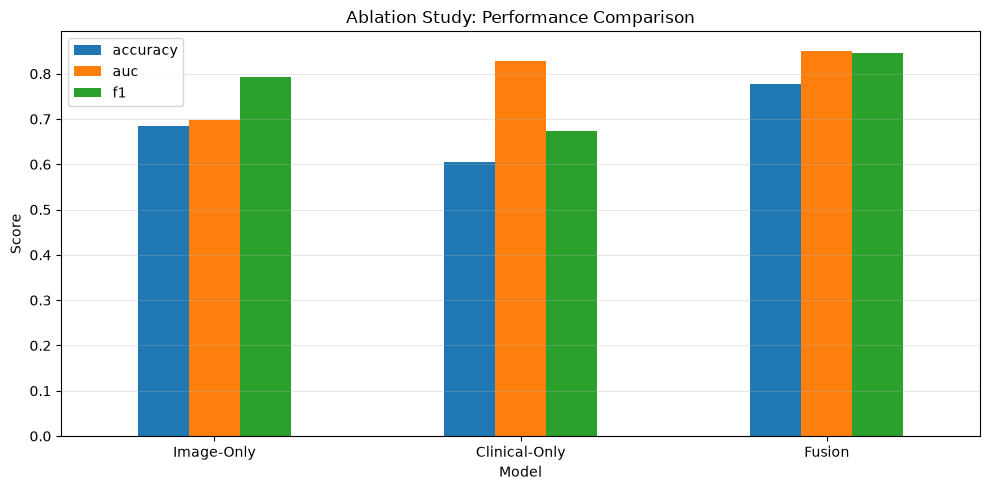


✅ Saved to results\ablation_results.csv


In [28]:
# ==================== CELL 10: Save Results ====================
results_df = pd.DataFrame(ablation_results)

print("\n" + "=" * 68)
print("ABLATION STUDY RESULTS (Test Set)")
print("=" * 68)
print(results_df.round(4).to_string(index=False))

results_df.to_csv(RESULT_DIR / "ablation_results.csv", index=False)

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
results_df.set_index("Model")[["accuracy", "auc", "f1"]].plot(
    kind="bar", ax=ax, rot=0
)
ax.set_title("Ablation Study: Performance Comparison")
ax.set_ylabel("Score")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(RESULT_DIR / "ablation_comparison.png", dpi=200)
plt.show()

print(f"\n✅ Saved to {RESULT_DIR / 'ablation_results.csv'}")

In [29]:
# ==================== CELL 11: Sanity Check ====================
print("\n" + "=" * 60)
print("SANITY CHECK: Ablation Results")
print("=" * 60)

for _, row in results_df.iterrows():
    print(f"\n{row['Model']}:")
    print(f"  AUC:       {row['auc']:.4f}")
    print(f"  Recall:    {row['recall']:.4f}")
    print(f"  Precision: {row['precision']:.4f}")

    if row['auc'] < 0.60:
        print(f"  ⚠️ WARNING: Very low AUC!")
    if row['recall'] < 0.50:
        print(f"  ⚠️ WARNING: Very low Recall!")

# Verify Fusion > best single modality
fusion_auc = results_df[results_df['Model'] == 'Fusion']['auc'].values[0]
best_single = results_df[results_df['Model'] != 'Fusion']['auc'].max()

print(f"\n{'='*60}")
print(f"KEY FINDING:")
print(f"  Best single modality AUC: {best_single:.4f}")
print(f"  Fusion AUC:                {fusion_auc:.4f}")
print(f"  Improvement:               {fusion_auc - best_single:+.4f}")
print(f"{'='*60}")

if fusion_auc > best_single:
    print("✅ SUCCESS: Fusion > Best single modality")
    print("   This confirms the multimodal advantage!")
else:
    print("⚠️ WARNING: Fusion did not outperform single modality")
    print("   Check Notebook 05 fusion training.")


SANITY CHECK: Ablation Results

Image-Only:
  AUC:       0.6969
  Recall:    0.7667
  Precision: 0.8214

Clinical-Only:
  AUC:       0.8271
  Recall:    0.5167
  Precision: 0.9688

Fusion:
  AUC:       0.8510
  Recall:    0.7833
  Precision: 0.9216

KEY FINDING:
  Best single modality AUC: 0.8271
  Fusion AUC:                0.8510
  Improvement:               +0.0240
✅ SUCCESS: Fusion > Best single modality
   This confirms the multimodal advantage!
